In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import random
from PIL import Image

In [2]:
print("TensorFlow Version:", tf.__version__)
print("NumPy Version:", np.__version__)
print("Pandas Version:", pd.__version__)

TensorFlow Version: 2.21.0
NumPy Version: 2.4.3
Pandas Version: 3.0.1


In [3]:
train_path = "../dataset/train"
test_path = "../dataset/test"

In [4]:
print(os.listdir(train_path))

['Acne and Rosacea Photos', 'Actinic Keratosis Basal Cell Carcinoma and other Malignant Lesions', 'Atopic Dermatitis Photos', 'Bullous Disease Photos', 'Cellulitis Impetigo and other Bacterial Infections', 'Eczema Photos', 'Exanthems and Drug Eruptions', 'Hair Loss Photos Alopecia and other Hair Diseases', 'Herpes HPV and other STDs Photos', 'Light Diseases and Disorders of Pigmentation', 'Lupus and other Connective Tissue diseases', 'Melanoma Skin Cancer Nevi and Moles', 'Nail Fungus and other Nail Disease', 'Poison Ivy Photos and other Contact Dermatitis', 'Psoriasis pictures Lichen Planus and related diseases', 'Scabies Lyme Disease and other Infestations and Bites', 'Seborrheic Keratoses and other Benign Tumors', 'Systemic Disease', 'Tinea Ringworm Candidiasis and other Fungal Infections', 'Urticaria Hives', 'Vascular Tumors', 'Vasculitis Photos', 'Warts Molluscum and other Viral Infections']


In [5]:
classes = sorted(os.listdir(train_path))

print("Total Disease Classes:", len(classes))
print()

for cls in classes:
    print(cls)

Total Disease Classes: 23

Acne and Rosacea Photos
Actinic Keratosis Basal Cell Carcinoma and other Malignant Lesions
Atopic Dermatitis Photos
Bullous Disease Photos
Cellulitis Impetigo and other Bacterial Infections
Eczema Photos
Exanthems and Drug Eruptions
Hair Loss Photos Alopecia and other Hair Diseases
Herpes HPV and other STDs Photos
Light Diseases and Disorders of Pigmentation
Lupus and other Connective Tissue diseases
Melanoma Skin Cancer Nevi and Moles
Nail Fungus and other Nail Disease
Poison Ivy Photos and other Contact Dermatitis
Psoriasis pictures Lichen Planus and related diseases
Scabies Lyme Disease and other Infestations and Bites
Seborrheic Keratoses and other Benign Tumors
Systemic Disease
Tinea Ringworm Candidiasis and other Fungal Infections
Urticaria Hives
Vascular Tumors
Vasculitis Photos
Warts Molluscum and other Viral Infections


In [6]:
image_count = []

for cls in classes:

    folder = os.path.join(train_path, cls)

    count = len(os.listdir(folder))

    image_count.append(count)

    print(f"{cls:<25} {count}")

Acne and Rosacea Photos   840
Actinic Keratosis Basal Cell Carcinoma and other Malignant Lesions 1149
Atopic Dermatitis Photos  489
Bullous Disease Photos    448
Cellulitis Impetigo and other Bacterial Infections 288
Eczema Photos             1235
Exanthems and Drug Eruptions 404
Hair Loss Photos Alopecia and other Hair Diseases 239
Herpes HPV and other STDs Photos 405
Light Diseases and Disorders of Pigmentation 568
Lupus and other Connective Tissue diseases 420
Melanoma Skin Cancer Nevi and Moles 463
Nail Fungus and other Nail Disease 1040
Poison Ivy Photos and other Contact Dermatitis 260
Psoriasis pictures Lichen Planus and related diseases 1405
Scabies Lyme Disease and other Infestations and Bites 431
Seborrheic Keratoses and other Benign Tumors 1371
Systemic Disease          606
Tinea Ringworm Candidiasis and other Fungal Infections 1300
Urticaria Hives           212
Vascular Tumors           482
Vasculitis Photos         416
Warts Molluscum and other Viral Infections 1086


In [7]:
df = pd.DataFrame({

    "Disease": classes,

    "Images": image_count

})

df

,Disease,Images
0,Acne and Rosacea Photos,840
1,Actinic Keratosis Basal Cell Carcinoma and oth...,1149
2,Atopic Dermatitis Photos,489
3,Bullous Disease Photos,448
4,Cellulitis Impetigo and other Bacterial Infect...,288
5,Eczema Photos,1235
6,Exanthems and Drug Eruptions,404
7,Hair Loss Photos Alopecia and other Hair Diseases,239
8,Herpes HPV and other STDs Photos,405
9,Light Diseases and Disorders of Pigmentation,568


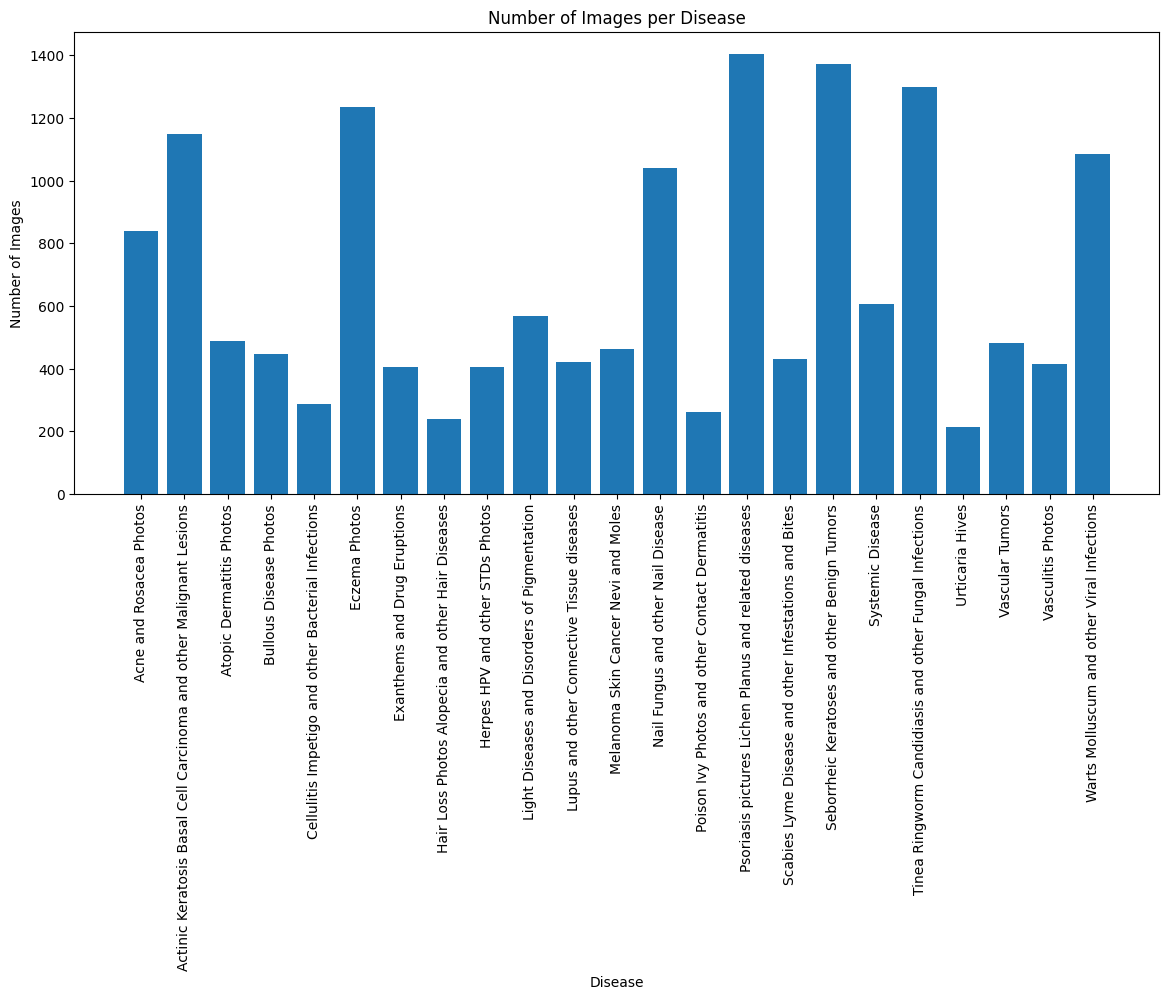

In [8]:
plt.figure(figsize=(14,6))

plt.bar(df["Disease"], df["Images"])

plt.xticks(rotation=90)

plt.xlabel("Disease")

plt.ylabel("Number of Images")

plt.title("Number of Images per Disease")

plt.show()

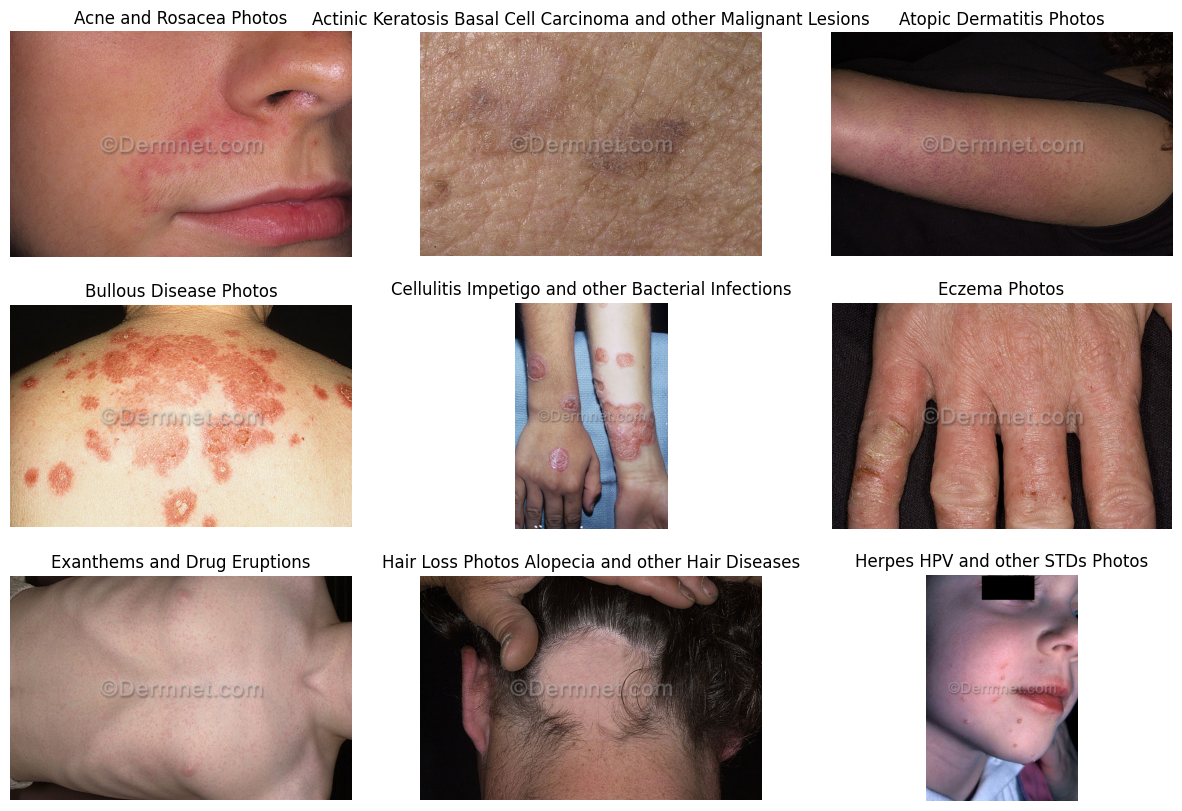

In [9]:
plt.figure(figsize=(15,10))

for i, cls in enumerate(classes[:9]):

    folder = os.path.join(train_path, cls)

    image_name = random.choice(os.listdir(folder))

    image_path = os.path.join(folder, image_name)

    image = Image.open(image_path)

    plt.subplot(3,3,i+1)

    plt.imshow(image)

    plt.title(cls)

    plt.axis("off")

plt.show()

In [10]:
total_images = sum(image_count)

print("Total Number of Classes :", len(classes))
print("Total Number of Images  :", total_images)
print("Average Images per Class:", round(np.mean(image_count),2))
print("Minimum Images in a Class:", min(image_count))
print("Maximum Images in a Class:", max(image_count))

Total Number of Classes : 23
Total Number of Images  : 15557
Average Images per Class: 676.39
Minimum Images in a Class: 212
Maximum Images in a Class: 1405


In [11]:

width = []
height = []

sample_size = 500

all_images = []

for cls in classes:
    folder = os.path.join(train_path, cls)

    for img in os.listdir(folder):
        all_images.append(os.path.join(folder, img))

sample_images = random.sample(all_images, sample_size)

for img_path in sample_images:

    image = Image.open(img_path)

    w, h = image.size

    width.append(w)
    height.append(h)

print("Minimum Width :", min(width))
print("Maximum Width :", max(width))
print("Average Width :", round(np.mean(width),2))

print()

print("Minimum Height :", min(height))
print("Maximum Height :", max(height))
print("Average Height :", round(np.mean(height),2))

Minimum Width : 456
Maximum Width : 720
Average Width : 653.83

Minimum Height : 427
Maximum Height : 720
Average Height : 549.56


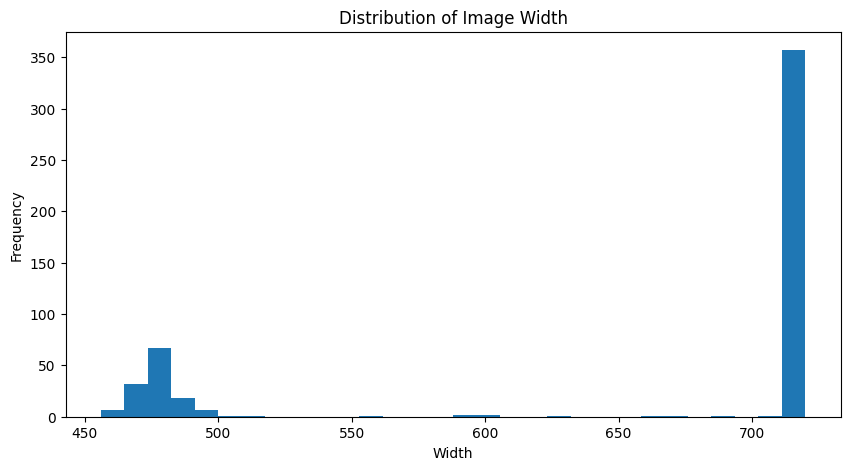

In [12]:
# ==========================================
# Width Distribution
# ==========================================

plt.figure(figsize=(10,5))

plt.hist(width, bins=30)

plt.title("Distribution of Image Width")

plt.xlabel("Width")

plt.ylabel("Frequency")

plt.show()

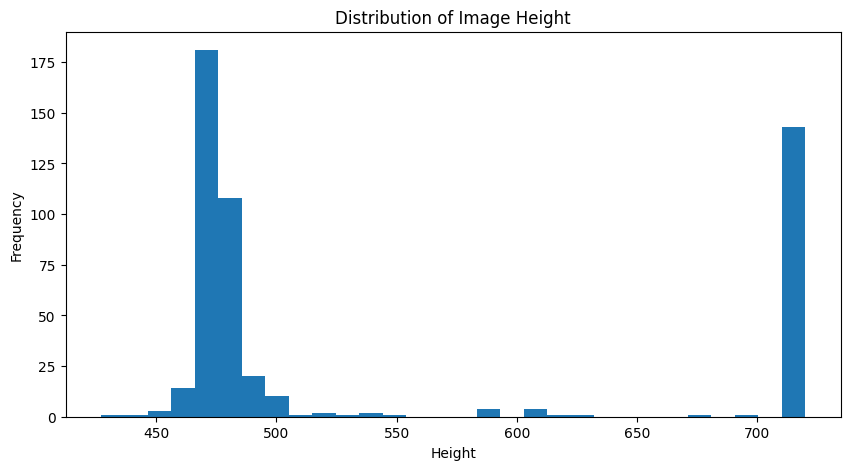

In [13]:
# ==========================================
# Height Distribution
# ==========================================

plt.figure(figsize=(10,5))

plt.hist(height, bins=30)

plt.title("Distribution of Image Height")

plt.xlabel("Height")

plt.ylabel("Frequency")

plt.show()

In [14]:
# ==========================================
# RGB Check
# ==========================================

sample_class = classes[0]

sample_folder = os.path.join(train_path, sample_class)

sample_image = random.choice(os.listdir(sample_folder))

sample_path = os.path.join(sample_folder, sample_image)

image = Image.open(sample_path)

print("Image Mode :", image.mode)

Image Mode : RGB


In [15]:
# ==========================================
# Image Information
# ==========================================

print("Image Size :", image.size)

print("Image Format :", image.format)

print("Image Mode :", image.mode)

Image Size : (720, 472)
Image Format : JPEG
Image Mode : RGB


In [16]:
# ==========================================
# Corrupted Image Detection
# ==========================================

corrupted = []

for cls in classes:

    folder = os.path.join(train_path, cls)

    for img in os.listdir(folder):

        try:

            Image.open(os.path.join(folder,img)).verify()

        except:

            corrupted.append(os.path.join(cls,img))

print("Total Corrupted Images :", len(corrupted))

Total Corrupted Images : 0


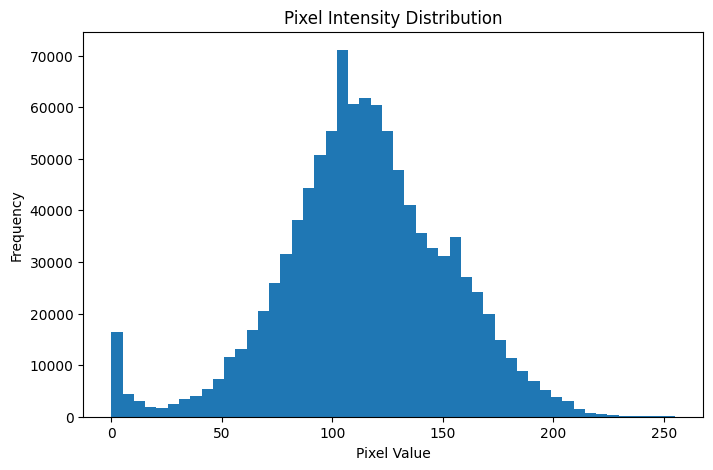

In [17]:
# ==========================================
# Pixel Value Distribution
# ==========================================

sample = np.array(image)

plt.figure(figsize=(8,5))

plt.hist(sample.ravel(), bins=50)

plt.title("Pixel Intensity Distribution")

plt.xlabel("Pixel Value")

plt.ylabel("Frequency")

plt.show()

In [18]:
# ==========================================
# Percentage of Images per Class
# ==========================================
df["Percentage"] = round(df["Images"] / total_images * 100, 2)

df

,Disease,Images,Percentage
0,Acne and Rosacea Photos,840,5.40
1,Actinic Keratosis Basal Cell Carcinoma and oth...,1149,7.39
2,Atopic Dermatitis Photos,489,3.14
3,Bullous Disease Photos,448,2.88
4,Cellulitis Impetigo and other Bacterial Infect...,288,1.85
5,Eczema Photos,1235,7.94
6,Exanthems and Drug Eruptions,404,2.60
7,Hair Loss Photos Alopecia and other Hair Diseases,239,1.54
8,Herpes HPV and other STDs Photos,405,2.60
9,Light Diseases and Disorders of Pigmentation,568,3.65


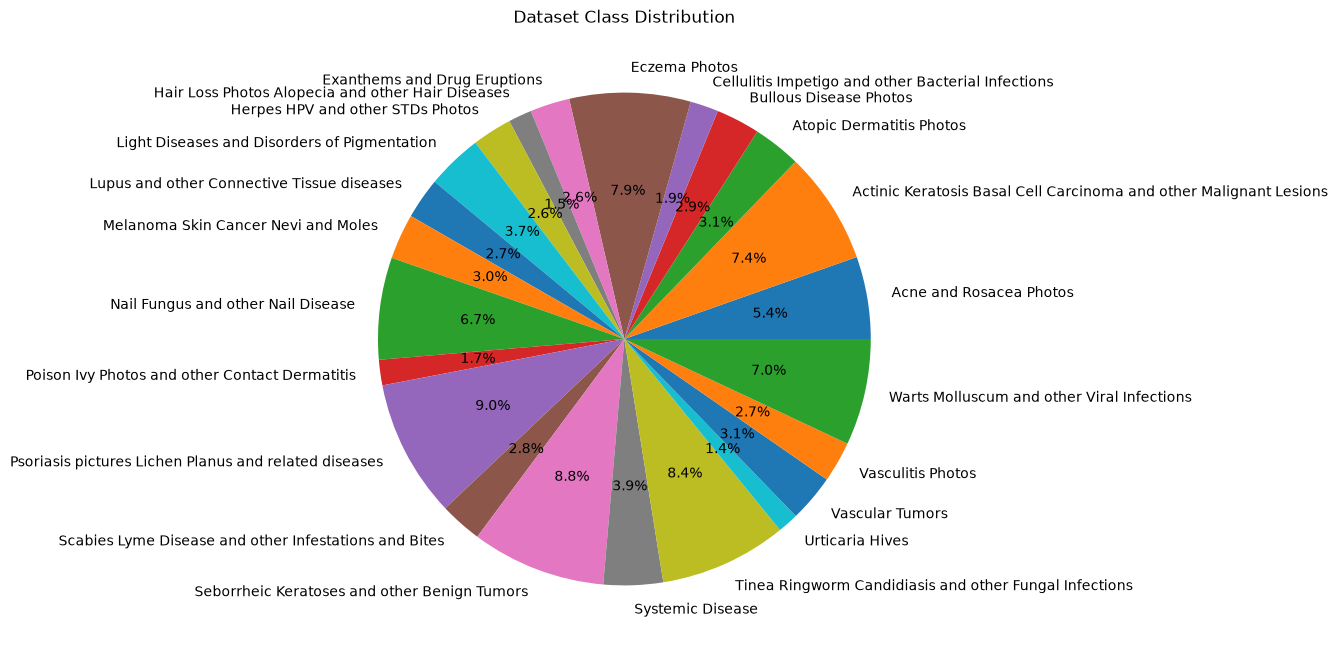

In [ ]:
# ==========================================
# Class Distribution Pie Chart
# ==========================================

plt.figure(figsize=(8,8))

plt.pie(df["Images"],
        labels=df["Disease"],
        autopct='%1.1f%%')

plt.title("Dataset Class Distribution")

plt.show()

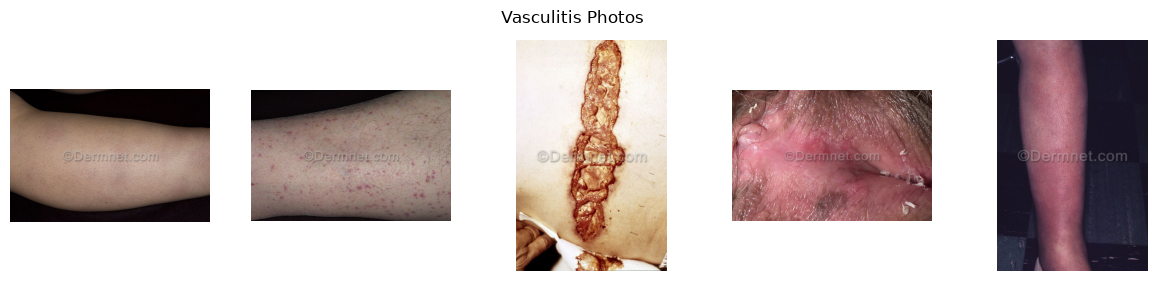

In [ ]:
# ==========================================
# Random Images from Same Disease
# ==========================================

selected_class = random.choice(classes)

folder = os.path.join(train_path, selected_class)

images = random.sample(os.listdir(folder),5)

plt.figure(figsize=(15,3))

for i,img in enumerate(images):

    image = Image.open(os.path.join(folder,img))

    plt.subplot(1,5,i+1)

    plt.imshow(image)

    plt.axis("off")

plt.suptitle(selected_class)

plt.show()

In [ ]:
# ==========================================
# Import Libraries
# ==========================================

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [ ]:
# ==========================================
# Parameters
# ==========================================

IMG_HEIGHT = 224
IMG_WIDTH = 224

BATCH_SIZE = 32

SEED = 42

In [ ]:
# ==========================================
# Load Training Dataset
# ==========================================

train_ds = tf.keras.utils.image_dataset_from_directory(

    train_path,

    validation_split=0.2,

    subset="training",

    seed=SEED,

    image_size=(IMG_HEIGHT, IMG_WIDTH),

    batch_size=BATCH_SIZE

)

Found 15557 files belonging to 23 classes.
Using 12446 files for training.


In [ ]:
# ==========================================
# Validation Dataset
# ==========================================

val_ds = tf.keras.utils.image_dataset_from_directory(

    train_path,

    validation_split=0.2,

    subset="validation",

    seed=SEED,

    image_size=(IMG_HEIGHT, IMG_WIDTH),

    batch_size=BATCH_SIZE

)

Found 15557 files belonging to 23 classes.
Using 3111 files for validation.


In [ ]:
# ==========================================
# Test Dataset
# ==========================================

test_ds = tf.keras.utils.image_dataset_from_directory(

    test_path,

    shuffle=False,

    image_size=(IMG_HEIGHT, IMG_WIDTH),

    batch_size=BATCH_SIZE

)

Found 4002 files belonging to 23 classes.


In [ ]:
# ==========================================
# Class Names
# ==========================================

class_names = train_ds.class_names

print(class_names)

['Acne and Rosacea Photos', 'Actinic Keratosis Basal Cell Carcinoma and other Malignant Lesions', 'Atopic Dermatitis Photos', 'Bullous Disease Photos', 'Cellulitis Impetigo and other Bacterial Infections', 'Eczema Photos', 'Exanthems and Drug Eruptions', 'Hair Loss Photos Alopecia and other Hair Diseases', 'Herpes HPV and other STDs Photos', 'Light Diseases and Disorders of Pigmentation', 'Lupus and other Connective Tissue diseases', 'Melanoma Skin Cancer Nevi and Moles', 'Nail Fungus and other Nail Disease', 'Poison Ivy Photos and other Contact Dermatitis', 'Psoriasis pictures Lichen Planus and related diseases', 'Scabies Lyme Disease and other Infestations and Bites', 'Seborrheic Keratoses and other Benign Tumors', 'Systemic Disease', 'Tinea Ringworm Candidiasis and other Fungal Infections', 'Urticaria Hives', 'Vascular Tumors', 'Vasculitis Photos', 'Warts Molluscum and other Viral Infections']


In [ ]:
# ==========================================
# Dataset Shape
# ==========================================

for images, labels in train_ds.take(1):

    print("Image Batch Shape :", images.shape)

    print("Label Batch Shape :", labels.shape)

Image Batch Shape : (32, 224, 224, 3)
Label Batch Shape : (32,)


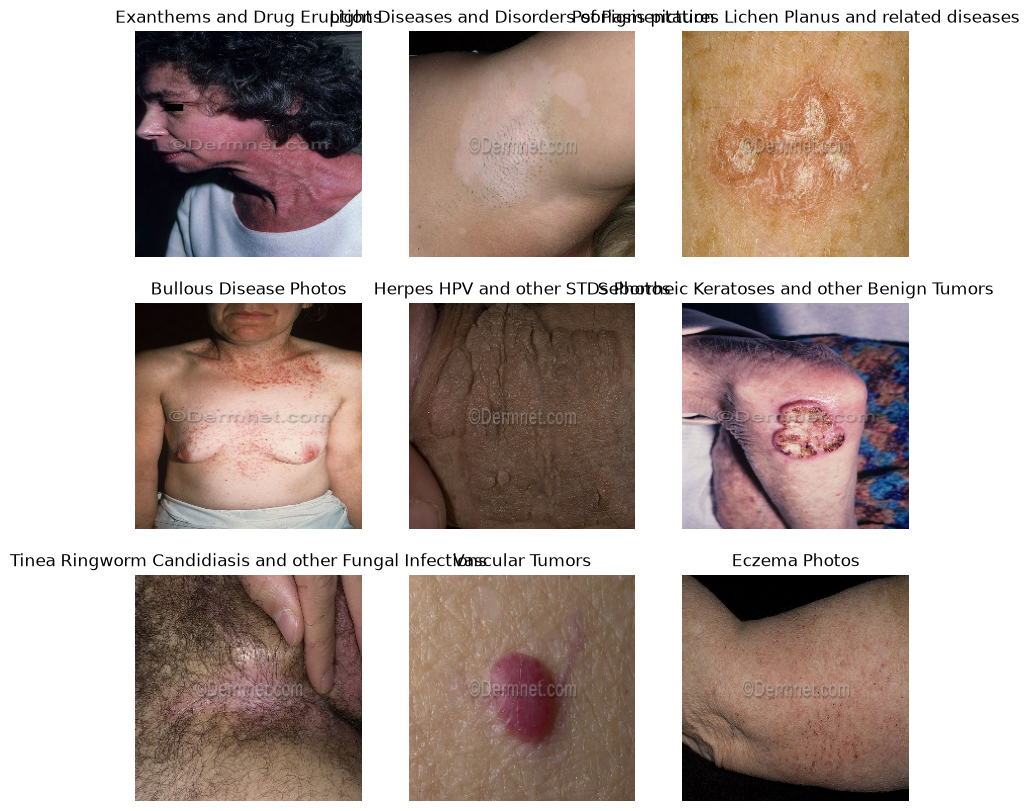

In [ ]:
# ==========================================
# Visualize Batch
# ==========================================

plt.figure(figsize=(10,10))

for images, labels in train_ds.take(1):

    for i in range(9):

        plt.subplot(3,3,i+1)

        plt.imshow(images[i].numpy().astype("uint8"))

        plt.title(class_names[labels[i]])

        plt.axis("off")

plt.show()

In [ ]:
# ==========================================
# Normalization Layer
# ==========================================

normalization_layer = layers.Rescaling(1./255)

In [ ]:
normalized_ds = train_ds.map(

    lambda x, y: (normalization_layer(x), y)

)

In [ ]:
for images, labels in normalized_ds.take(1):

    print("Minimum Pixel :", tf.reduce_min(images).numpy())

    print("Maximum Pixel :", tf.reduce_max(images).numpy())

Minimum Pixel : 0.0
Maximum Pixel : 1.0


In [ ]:
# ==========================================
# Data Augmentation
# ==========================================

data_augmentation = keras.Sequential([

    layers.RandomFlip("horizontal"),

    layers.RandomRotation(0.1),

    layers.RandomZoom(0.1),

    layers.RandomContrast(0.1)

])

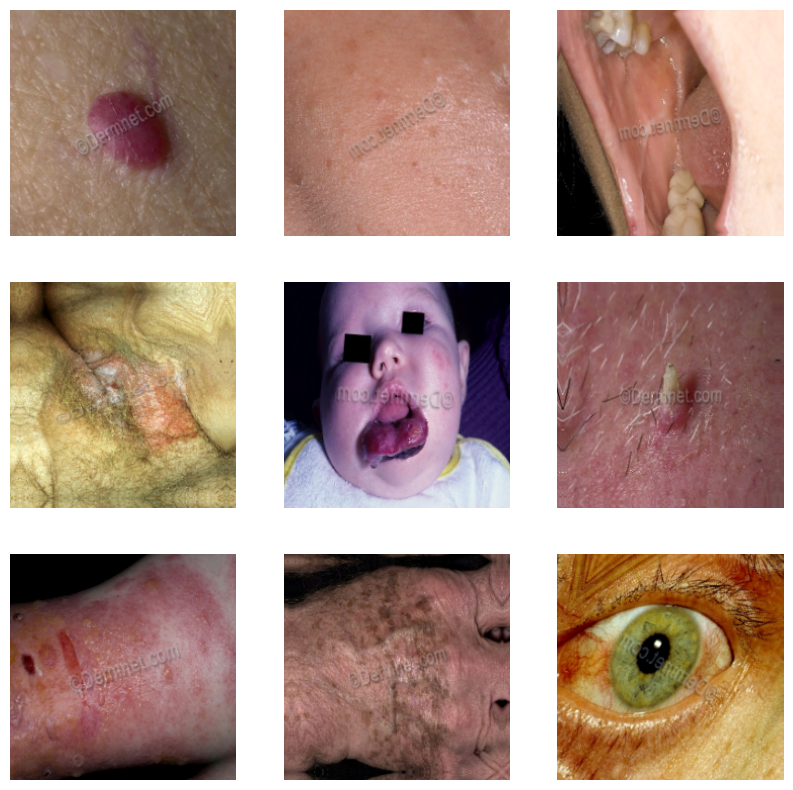

In [ ]:
plt.figure(figsize=(10,10))

for images, labels in train_ds.take(1):

    augmented_images = data_augmentation(images)

    for i in range(9):

        plt.subplot(3,3,i+1)

        plt.imshow(augmented_images[i].numpy().astype("uint8"))

        plt.axis("off")

plt.show()

In [ ]:
# ==========================================
# Improve Performance
# ==========================================

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)

val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

In [ ]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Rescaling,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

model = Sequential([
    
    # ----------------------------------
    # Input Layer + Normalization
    # ----------------------------------
    Rescaling(1./255, input_shape=(224, 224, 3)),
    
    
    # ----------------------------------
    # First Convolution Block
    # ----------------------------------
    Conv2D(
        filters=32,
        kernel_size=(3,3),
        activation='relu',
        padding='same'
    ),

    MaxPooling2D(pool_size=(2,2)),
    
    
    # ----------------------------------
    # Second Convolution Block
    # ----------------------------------
    Conv2D(
        filters=64,
        kernel_size=(3,3),
        activation='relu',
        padding='same'
    ),

    MaxPooling2D(pool_size=(2,2)),
    
    
    # ----------------------------------
    # Third Convolution Block
    # ----------------------------------
    Conv2D(
        filters=128,
        kernel_size=(3,3),
        activation='relu',
        padding='same'
    ),

    MaxPooling2D(pool_size=(2,2)),
    
    
    # ----------------------------------
    # Convert Feature Maps to Vector
    # ----------------------------------
    Flatten(),
    
    
    # ----------------------------------
    # Fully Connected Layer
    # ----------------------------------
    Dense(256, activation='relu'),
    
    
    # ----------------------------------
    # Dropout
    # ----------------------------------
    Dropout(0.5),
    
    
    # ----------------------------------
    # Output Layer
    # ----------------------------------
    Dense(len(class_names), activation='softmax')

])

print("CNN Model Created Successfully!")

CNN Model Created Successfully!


c:\Users\DELL\Documents\SkinDiseaseAI\venv\Lib\site-packages\keras\src\layers\preprocessing\data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    25,690,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 23)             │         5,911 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,789,527 (98.38 MB)

 Trainable params: 25,789,527 (98.38 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# ==========================================
# Compile the Model
# ==========================================

model.compile(

    optimizer='adam',

    loss='sparse_categorical_crossentropy',

    metrics=['accuracy']

)

In [ ]:
# ==========================================
# Train the Model
# ==========================================

history = model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=20

)

Epoch 1/20


c:\Users\DELL\Documents\SkinDiseaseAI\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


389/389 ━━━━━━━━━━━━━━━━━━━━ 149s 381ms/step - accuracy: 0.1272 - loss: 2.9787 - val_accuracy: 0.1823 - val_loss: 2.7823
Epoch 2/20
389/389 ━━━━━━━━━━━━━━━━━━━━ 153s 393ms/step - accuracy: 0.1743 - loss: 2.7799 - val_accuracy: 0.1948 - val_loss: 2.7346
Epoch 3/20
389/389 ━━━━━━━━━━━━━━━━━━━━ 159s 408ms/step - accuracy: 0.2193 - loss: 2.6364 - val_accuracy: 0.2083 - val_loss: 2.6888
Epoch 4/20
389/389 ━━━━━━━━━━━━━━━━━━━━ 152s 391ms/step - accuracy: 0.2800 - loss: 2.4098 - val_accuracy: 0.2231 - val_loss: 2.6947
Epoch 5/20
389/389 ━━━━━━━━━━━━━━━━━━━━ 160s 412ms/step - accuracy: 0.3599 - loss: 2.1328 - val_accuracy: 0.2302 - val_loss: 2.7454
Epoch 6/20
389/389 ━━━━━━━━━━━━━━━━━━━━ 153s 393ms/step - accuracy: 0.4434 - loss: 1.8490 - val_accuracy: 0.2356 - val_loss: 3.0441
Epoch 7/20
389/389 ━━━━━━━━━━━━━━━━━━━━ 227s 585ms/step - accuracy: 0.5167 - loss: 1.5946 - val_accuracy: 0.2440 - val_loss: 3.1121
Epoch 8/20
389/389 ━━━━━━━━━━━━━━━━━━━━ 164s 420ms/step - accuracy: 0.5901 - loss: 1.35

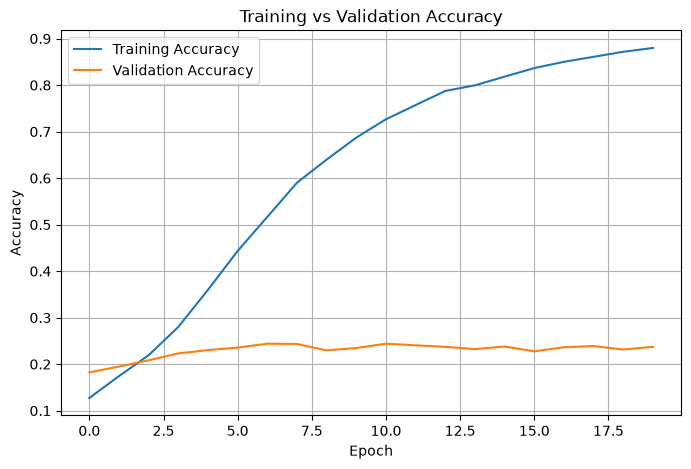

In [ ]:
# ==========================================
# Training & Validation Accuracy
# ==========================================

plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'], label='Training Accuracy')

plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.title("Training vs Validation Accuracy")

plt.legend()

plt.grid(True)

plt.show()

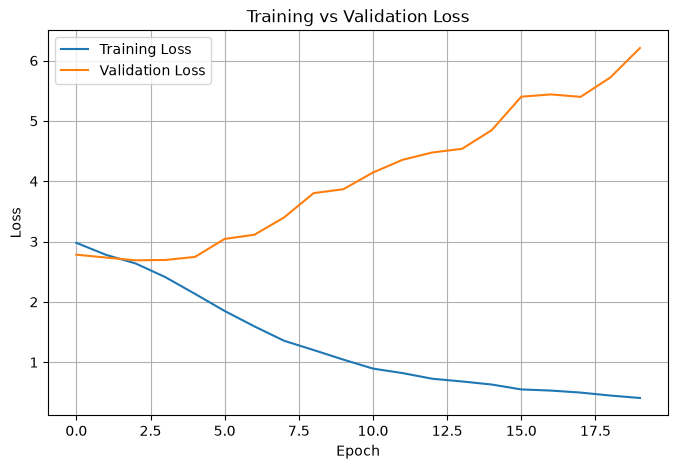

In [ ]:
# ==========================================
# Training & Validation Loss
# ==========================================

plt.figure(figsize=(8,5))

plt.plot(history.history['loss'], label='Training Loss')

plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("Training vs Validation Loss")

plt.legend()

plt.grid(True)

plt.show()

In [ ]:
# ==========================================
# Test Accuracy
# ==========================================

test_loss, test_accuracy = model.evaluate(test_ds)

print(f"\nTest Accuracy : {test_accuracy*100:.2f}%")

print(f"Test Loss : {test_loss:.4f}")

126/126 ━━━━━━━━━━━━━━━━━━━━ 40s 314ms/step - accuracy: 0.2626 - loss: 5.9409

Test Accuracy : 26.26%
Test Loss : 5.9409


In [ ]:
print("Training Accuracy:")
print(history.history['accuracy'])

Training Accuracy:
[0.12718945741653442, 0.17427286505699158, 0.21926723420619965, 0.2800096273422241, 0.3598746657371521, 0.4434356391429901, 0.5167121887207031, 0.590149462223053, 0.6398842930793762, 0.6872087121009827, 0.7265788316726685, 0.7571107149124146, 0.7874819040298462, 0.7995339632034302, 0.8182548880577087, 0.8366543650627136, 0.8500723242759705, 0.8608388304710388, 0.8716856837272644, 0.8798007369041443]


In [ ]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    25,690,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 23)             │         5,911 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 77,368,583 (295.14 MB)

 Trainable params: 25,789,527 (98.38 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 51,579,056 (196.76 MB)

In [ ]:
import pandas as pd

history_df = pd.DataFrame({
    "Epoch": range(1, len(history.history['accuracy'])+1),
    "Train Accuracy": history.history['accuracy'],
    "Validation Accuracy": history.history['val_accuracy'],
    "Train Loss": history.history['loss'],
    "Validation Loss": history.history['val_loss']
})

history_df

,Epoch,Train Accuracy,Validation Accuracy,Train Loss,Validation Loss
0,1,0.127189,0.182257,2.978713,2.782329
1,2,0.174273,0.194793,2.779879,2.734610
2,3,0.219267,0.208293,2.636386,2.688847
3,4,0.280010,0.223079,2.409812,2.694716
4,5,0.359875,0.230151,2.132755,2.745421
5,6,0.443436,0.235616,1.849027,3.044064
6,7,0.516712,0.243973,1.594594,3.112078
7,8,0.590149,0.243330,1.356141,3.398256
8,9,0.639884,0.229508,1.201695,3.802819
9,10,0.687209,0.234651,1.043107,3.866943


In [2]:
import os

train_path = "../dataset/train"
test_path = "../dataset/test"

print("Train exists:", os.path.exists(train_path))
print("Test exists:", os.path.exists(test_path))

print("\nClasses:")
print(os.listdir(train_path))

Train exists: True
Test exists: True

Classes:
['Acne and Rosacea Photos', 'Actinic Keratosis Basal Cell Carcinoma and other Malignant Lesions', 'Atopic Dermatitis Photos', 'Bullous Disease Photos', 'Cellulitis Impetigo and other Bacterial Infections', 'Eczema Photos', 'Exanthems and Drug Eruptions', 'Hair Loss Photos Alopecia and other Hair Diseases', 'Herpes HPV and other STDs Photos', 'Light Diseases and Disorders of Pigmentation', 'Lupus and other Connective Tissue diseases', 'Melanoma Skin Cancer Nevi and Moles', 'Nail Fungus and other Nail Disease', 'Poison Ivy Photos and other Contact Dermatitis', 'Psoriasis pictures Lichen Planus and related diseases', 'Scabies Lyme Disease and other Infestations and Bites', 'Seborrheic Keratoses and other Benign Tumors', 'Systemic Disease', 'Tinea Ringworm Candidiasis and other Fungal Infections', 'Urticaria Hives', 'Vascular Tumors', 'Vasculitis Photos', 'Warts Molluscum and other Viral Infections']
